In [1]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import numpy as np
from sklearn.impute import SimpleImputer

from math import sqrt
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder

In [2]:
headers = [ "Class", "age", "menopause", "tumor-size", "inv-nodes", "node-caps", "deg-malig", "breast", "breast-quad", "irradiat" ]

In [ ]:
headers = [
    "Class Name",
    "handicapped-infants",
    "water-project-cost-sharing",
    "adoption-of-the-budget-resolution",
    "physician-fee-freeze",
    "el-salvador-aid",
    "religious-groups-in-schools",
    "anti-satellite-test-ban",
    "aid-to-nicaraguan-contras",
    "mx-missile",
    "immigration",
    "synfuels-corporation-cutback",
    "education-spending",
    "superfund-right-to-sue",
    "crime",
    "duty-free-exports",
    "export-administration-act-south-africa"
    ]

In [ ]:
headers = [
    "Class","Alcohol", "Malic acid", "Ash", "Alcalinity of ash", "Magnesium",
    "Total phenols", "Flavanoids", "Nonflavanoid phenols", "Proanthocyanins",
    "Color intensity", "Hue", "OD280/OD315 of diluted wines", "Proline"
]

## Pre processing


### wine dataset

In [4]:
filepath = "explainability_cgt/datasets/wine_quality.csv"

In [5]:
df = pd.read_csv(filepath, header=0)

In [6]:
print(df.columns.tolist())

['Class', 'Alcohol', 'Malic acid', 'Ash', 'Alcalinity of ash', 'Magnesium', 'Total phenols', 'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins', 'Color intensity', 'Hue', 'OD280/OD315 of diluted wines', 'Proline']


In [7]:
feature_names= [
"Alcohol", "Malic acid", "Ash", "Alcalinity of ash", "Magnesium",
    "Total phenols", "Flavanoids", "Nonflavanoid phenols", "Proanthocyanins",
    "Color intensity", "Hue", "OD280/OD315 of diluted wines", "Proline"
]

In [8]:
X = df.drop("Class", axis=1)
y = df["Class"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, train_size=0.8, stratify=y, random_state=42
)

In [11]:
np.savez("explainability_cgt/datasets/wine/wine_preprocessed.npz",
         X_train=X_train, X_test=X_test,
         y_train=y_train, y_test=y_test, feature_names=feature_names)

### congress dataset

In [12]:
filepath = "explainability_cgt/datasets/congress/congressional_voting.csv"

In [13]:
df = pd.read_csv(filepath, header=0)

In [14]:
df.head()

,Class Name,handicapped-infants,water-project-cost-sharing,adoption-of-the-budget-resolution,physician-fee-freeze,el-salvador-aid,religious-groups-in-schools,anti-satellite-test-ban,aid-to-nicaraguan-contras,mx-missile,immigration,synfuels-corporation-cutback,education-spending,superfund-right-to-sue,crime,duty-free-exports,export-administration-act-south-africa
0,republican,n,y,n,y,y,y,n,n,n,n,n,y,y,y,n,?
1,democrat,?,y,y,?,y,y,n,n,n,n,y,n,y,y,n,n
2,democrat,n,y,y,n,?,y,n,n,n,n,y,n,y,n,n,y
3,democrat,y,y,y,n,y,y,n,n,n,n,y,?,y,y,y,y
4,democrat,n,y,y,n,y,y,n,n,n,n,n,n,y,y,y,y


In [15]:
X = df.drop("Class Name", axis=1)
y = df["Class Name"]

In [16]:
X = X.replace({'y': 1, 'n': 0, '?': np.nan})

In [17]:
imputer = SimpleImputer(strategy="most_frequent")
X_imputed = imputer.fit_transform(X)

In [18]:
X_imputed

array([[0., 1., 0., ..., 1., 0., 1.],
       [0., 1., 1., ..., 1., 0., 0.],
       [0., 1., 1., ..., 0., 0., 1.],
       ...,
       [0., 1., 0., ..., 1., 0., 1.],
       [0., 0., 0., ..., 1., 0., 1.],
       [0., 1., 0., ..., 1., 0., 0.]])

In [19]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X_imputed, y_encoded, train_size=0.8, stratify=y_encoded, random_state=42
)

In [21]:
feature_names = [
    "handicapped-infants",
    "water-project-cost-sharing",
    "adoption-of-the-budget-resolution",
    "physician-fee-freeze",
    "el-salvador-aid",
    "religious-groups-in-schools",
    "anti-satellite-test-ban",
    "aid-to-nicaraguan-contras",
    "mx-missile",
    "immigration",
    "synfuels-corporation-cutback",
    "education-spending",
    "superfund-right-to-sue",
    "crime",
    "duty-free-exports",
    "export-administration-act-south-africa"
    ]

In [22]:
np.savez("explainability_cgt/datasets/congress/congress_preprocessed.npz",
         X_train=X_train, X_test=X_test,
         y_train=y_train, y_test=y_test, feature_names = feature_names)

### breast cancer

In [52]:
headers = [ "Sample_code_number", "Clump_thickness", "Uniformity_of_cell_size", "Uniformity_of_cell_shape", "Marginal_adhesion", "Single_epithelial_cell_size", "Bare_nuclei","Bland_chromatin", "Normal_nucleoli", "Mitoses", "Class" ]


df = pd.read_csv("datasets/breast_cancer/breast+cancer+wisconsin+original/breast-cancer-wisconsin.data",  skiprows=1, header=None, names=headers)

df.to_csv("datasets/breast_cancer/breast_cancer.csv", index=False)

In [2]:
filepath = "datasets/breast_cancer/breast_cancer.csv"

In [3]:
df = pd.read_csv(filepath, header=0)

In [4]:
df = df[df['Bare_nuclei'] != '?']

In [5]:
df['Bare_nuclei'] = pd.to_numeric(df['Bare_nuclei'])

In [6]:
df.shape

(682, 11)

In [7]:
df = df.dropna()

In [8]:
df.shape

(682, 11)

In [9]:
df.head()

,Sample_code_number,Clump_thickness,Uniformity_of_cell_size,Uniformity_of_cell_shape,Marginal_adhesion,Single_epithelial_cell_size,Bare_nuclei,Bland_chromatin,Normal_nucleoli,Mitoses,Class
0,1002945,5,4,4,5,7,10,3,2,1,2
1,1015425,3,1,1,1,2,2,3,1,1,2
2,1016277,6,8,8,1,3,4,3,7,1,2
3,1017023,4,1,1,3,2,1,3,1,1,2
4,1017122,8,10,10,8,7,10,9,7,1,4


In [10]:
y = df["Class"]
X = df.drop(["Class","Sample_code_number"], axis=1)

In [11]:
X.dtypes

Clump_thickness                int64
Uniformity_of_cell_size        int64
Uniformity_of_cell_shape       int64
Marginal_adhesion              int64
Single_epithelial_cell_size    int64
Bare_nuclei                    int64
Bland_chromatin                int64
Normal_nucleoli                int64
Mitoses                        int64
dtype: object

In [12]:
X
y_encoded = LabelEncoder().fit_transform(y)

In [13]:
y_encoded

array([0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1,
       0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1,
       1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0,

In [14]:
feature_names = headers = ["Clump_thickness", "Uniformity_of_cell_size", "Uniformity_of_cell_shape", "Marginal_adhesion", "Single_epithelial_cell_size", "Bare_nuclei","Bland_chromatin", "Normal_nucleoli", "Mitoses"]

In [15]:
feature_names

['Clump_thickness',
 'Uniformity_of_cell_size',
 'Uniformity_of_cell_shape',
 'Marginal_adhesion',
 'Single_epithelial_cell_size',
 'Bare_nuclei',
 'Bland_chromatin',
 'Normal_nucleoli',
 'Mitoses']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, train_size=0.8, random_state=42
)

<Axes: >

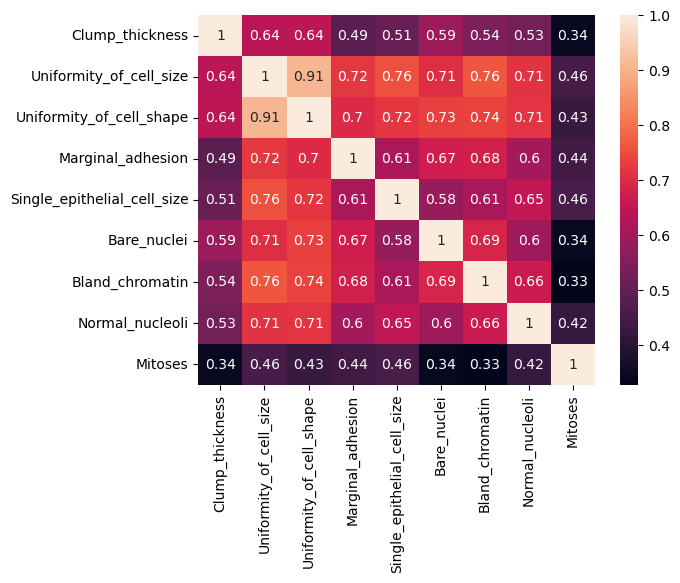

In [17]:
import seaborn as sns
corr_matrix = X_train.corr()
sns.heatmap(corr_matrix, annot=True)

In [19]:
print(corr_matrix)

                             Clump_thickness  Uniformity_of_cell_size  \
Clump_thickness                     1.000000                 0.637279   
Uniformity_of_cell_size             0.637279                 1.000000   
Uniformity_of_cell_shape            0.641047                 0.906736   
Marginal_adhesion                   0.487028                 0.720947   
Single_epithelial_cell_size         0.507861                 0.755008   
Bare_nuclei                         0.588798                 0.705149   
Bland_chromatin                     0.543277                 0.762177   
Normal_nucleoli                     0.526638                 0.711800   
Mitoses                             0.342538                 0.455498   

                             Uniformity_of_cell_shape  Marginal_adhesion  \
Clump_thickness                              0.641047           0.487028   
Uniformity_of_cell_size                      0.906736           0.720947   
Uniformity_of_cell_shape                 

apple quality

In [4]:
filepath = "datasets/apple_quality/apple_quality.csv"

In [5]:
df = pd.read_csv(filepath, header=0)

In [9]:
df.head()

,Size,Weight,Sweetness,Crunchiness,Juiciness,Ripeness,Acidity,Quality
0,-3.970049,-2.512336,5.346330,-1.012009,1.844900,0.329840,-0.491590483,good
1,-1.195217,-2.839257,3.664059,1.588232,0.853286,0.867530,-0.722809367,good
2,-0.292024,-1.351282,-1.738429,-0.342616,2.838636,-0.038033,2.621636473,bad
3,-0.657196,-2.271627,1.324874,-0.097875,3.637970,-3.413761,0.790723217,good
4,1.364217,-1.296612,-0.384658,-0.553006,3.030874,-1.303849,0.501984036,good


In [7]:
df = df.dropna()

In [8]:
df.drop(columns=['A_id'], inplace=True)

In [10]:
feature_names = df.columns.tolist()

In [11]:
feature_names.remove('Quality')

In [13]:
y = df["Quality"]
X = df.drop("Quality", axis=1)
y = [1 if val == "good" else 0 for val in y]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, stratify=y, random_state=42
)

In [14]:
np.savez("datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
         X_train=X_train, X_test=X_test,
         y_train=y_train, y_test=y_test, feature_names=feature_names)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

filepath = "datasets/apple_quality/apple_quality.csv"
df = pd.read_csv(filepath, header=0)
df.drop(columns=['A_id'], inplace=True)

for col in df.columns:
    if col != 'Quality':
        df[col] = pd.to_numeric(df[col], errors='coerce')

df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

y = df["Quality"].map({'bad': 0, 'good': 1})
X = df.drop("Quality", axis=1)

feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=42
)

np.savez("datasets/apple_quality/apple_quality_preprocessed_no_scaling.npz",
         X_train=X_train, X_test=X_test,
         y_train=y_train, y_test=y_test, feature_names=feature_names)

# Dog vs fish dataset

In [ ]:
import numpy as np
import torch
from datasets import load_dataset, Dataset, DatasetDict, enable_progress_bar
from torch.utils.data import DataLoader
from torchvision.models import inception_v3, Inception_V3_Weights
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from pathlib import Path
import os

# Set a specific cache directory if needed
from datasets import config
config.HF_DATASETS_CACHE = "hf_cache"

enable_progress_bar()

# The same class indices used in the original paper
IMAGENET_DOG_LABELS = list(range(151, 276))
IMAGENET_FISH_LABELS = list(range(0, 15)) + list(range(389, 398))

OUTPUT_DIR = Path("datasets/dog_vs_fish")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Define a seed for reproducibility
SEED = 42

Setup complete.


In [ ]:
print("📦 Loading the full ImageNet-1k dataset...")
full_ds = load_dataset("ILSVRC/imagenet-1k")
train_ds = full_ds["train"]

print("\n Filtering for dogs and fish...")
dog_train = train_ds.filter(lambda x: x["label"] in IMAGENET_DOG_LABELS, num_proc=4)
fish_train = train_ds.filter(lambda x: x["label"] in IMAGENET_FISH_LABELS, num_proc=4)
print(f"Found {len(dog_train)} dog images and {len(fish_train)} fish images")

print("\n✂️ Subsampling to 600 images per class...")
dog_train = dog_train.shuffle(seed=SEED).select(range(600))
fish_train = fish_train.shuffle(seed=SEED).select(range(600))

all_samples = []
for example in dog_train:
    example['binary_label'] = 0
    all_samples.append(example)

for example in fish_train:
    example['binary_label'] = 1
    all_samples.append(example)

print("\nCombining and shuffling the dataset...")
combined_ds = Dataset.from_list(all_samples).shuffle(seed=SEED)

📦 Loading the full ImageNet-1k dataset...

🔍 Filtering for dogs and fish...


Found 156973 dog images and 30734 fish images

✂️ Subsampling to 600 images per class...

Combining and shuffling the dataset...


In [13]:
from datasets import ClassLabel, Features
print("\nCasting 'binary_label' to a categorical type for stratification...")
features = combined_ds.features
features["binary_label"] = ClassLabel(names=["dog", "fish"])
combined_ds = combined_ds.cast(features)
combined_ds = combined_ds.shuffle(seed=SEED)


Casting 'binary_label' to a categorical type for stratification...


In [14]:
# Split the combined dataset for train/validation
print("\nSplitting the dataset...")
split_ds = combined_ds.train_test_split(test_size=0.5, stratify_by_column="binary_label", seed=SEED)

print("\nStep 1 complete. Final image dataset created:")
print(split_ds)


Splitting the dataset...

✅ Step 1 complete. Final image dataset created:
DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'binary_label'],
        num_rows: 600
    })
    test: Dataset({
        features: ['image', 'label', 'binary_label'],
        num_rows: 600
    })
})


In [15]:
split_ds.save_to_disk(OUTPUT_DIR / "dog_vs_fish_raw")

In [16]:
print("Setting up Inception V3 for feature extraction...")
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

pretrained_weights = Inception_V3_Weights.IMAGENET1K_V1
inception_model = inception_v3(weights=pretrained_weights).to(device)
inception_model.eval()

class Identity(torch.nn.Module):
    def forward(self, x):
        return x
inception_model.fc = Identity()

# Get transformations and apply them to the dataset
preprocess = pretrained_weights.transforms()
def transform(batch):
    # Ensure all images are RGB and apply preprocessing
    batch["image"] = [preprocess(img.convert("RGB")) for img in batch["image"]]
    return batch
split_ds.set_transform(transform)

print(" Generating embeddings for all images...")
train_dataloader = DataLoader(split_ds["train"], batch_size=32)
val_dataloader = DataLoader(split_ds["test"], batch_size=32)

all_embeddings = []
all_labels = []

with torch.no_grad():
    for batch in tqdm(train_dataloader, desc="Training Set"):
        images = batch["image"].to(device)
        labels = batch["binary_label"]
        output = inception_model(images)
        all_embeddings.append(output.cpu().numpy())
        all_labels.append(labels.numpy())

    for batch in tqdm(val_dataloader, desc="Validation Set"):
        images = batch["image"].to(device)
        labels = batch["binary_label"]
        output = inception_model(images)
        all_embeddings.append(output.cpu().numpy())
        all_labels.append(labels.numpy())

X = np.concatenate(all_embeddings, axis=0)
y = np.concatenate(all_labels, axis=0)

print("Generated embeddings.")
print(f"Shape of X (embeddings): {X.shape}")
print(f"Shape of y (labels): {y.shape}")

Setting up Inception V3 for feature extraction...
Using device: cuda
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to .cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


 Generating embeddings for all images...


Generated embeddings.
Shape of X (embeddings): (1200, 2048)
Shape of y (labels): (1200,)


In [1]:
print("Splitting data into a final train and test set (50/50)...")
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    train_size=0.5,
    stratify=y,
    random_state=SEED
)

npz_path = OUTPUT_DIR / "dog_vs_fish_dataset.npz"
print(f" Saving final dataset to {npz_path}...")
np.savez(
    npz_path,
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

print(f" Dataset creation complete!")
print(f"Dataset saved to: {npz_path}")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Feature dimensionality: {X_train.shape[1]}")

Splitting data into a final train and test set (50/50)...


# Synthetic data generation

In [ ]:
np.random.seed(42)

n_samples = 200
n_features = 50
n_test_samples = 200

X = np.random.multivariate_normal(
    mean=np.zeros(n_features),
    cov=np.eye(n_features),
    size=n_samples + n_test_samples
)


feature_mask = np.random.random(n_features) > 0.5


Xb = X @ feature_mask
Xb -= np.mean(Xb)

pr = 1 / (1 + np.exp(-Xb))

y = (pr > np.random.random(n_samples + n_test_samples)).astype(int)

X_train, X_test = X[:n_samples], X[n_samples:]
y_train, y_test = y[:n_samples], y[n_samples:]


np.savez(
    "datasets/synthetic_data/synethetic_dataset.npz",
    X_train=X_train,
    X_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Synthetic yield data

In [48]:
df = pd.read_csv("datasets/yield_synthetic/raw_data.csv")

In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.inspection import permutation_importance

In [50]:
X = df[[  "irrigation", "N", "herbicide"]]
y = df["yield"]

In [13]:
filepath = "datasets/yield_synthetic/synthetic_translog_agriculture.csv"

In [14]:
df = pd.read_csv(filepath, header=0)

In [17]:
df.head()

,Nitrogen,Irrigation,Precipitation,Herbicide,Yield
0,254.901425,348.622989,146.222894,4378.494308,84747.326006
1,235.852071,364.862762,186.024999,3538.917338,91764.378216
2,259.430656,406.644099,210.209748,4434.802960,117434.973789
3,285.690896,404.304164,211.879224,4677.818929,126231.009870
4,232.975399,209.786451,191.997381,4206.717452,61303.113068


In [16]:
df.drop(columns = ["elas_N","elas_I","elas_H","elas_P"], inplace=True)

In [18]:
y = df["Yield"]
X = df.drop("Yield", axis=1)

In [19]:
feature_names = df.columns.tolist()

In [20]:
feature_names.remove("Yield")

In [21]:
feature_names

['Nitrogen', 'Irrigation', 'Precipitation', 'Herbicide']

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.8, random_state=42
)

In [24]:
np.savez("datasets/yield_synthetic/yield_preprocessed.npz",
         X_train=X_train, X_test=X_test,
         y_train=y_train, y_test=y_test, feature_names=feature_names)

# synthetic lung cancer dataset

In [ ]:
np.random.seed(42)

n = 1000


smoking = np.random.normal(loc=5, scale=sqrt(2), size=n)
stress  = np.random.normal(loc=5, scale=sqrt(2), size=n)


eps_risk   = np.random.normal(loc=0, scale=sqrt(3), size=n)
eps_coffee = np.random.normal(loc=0, scale=1.0, size=n)

lung_cancer_risk = 2.0 * smoking + 1.2 * stress + eps_risk
drink_coffee     = 2.0 * smoking + 1.0 * stress + eps_coffee

In [3]:
df = pd.DataFrame({
    "smoking": smoking,
    "stress": stress,
    "drink_coffee": drink_coffee,
    "lung_cancer_risk": lung_cancer_risk
})

In [4]:
df.head()

,smoking,stress,drink_coffee,lung_cancer_risk
0,5.702460,6.978987,16.476100,18.610262
1,4.804465,6.307629,15.056174,16.927771
2,5.915970,5.084330,16.502664,16.560624
3,7.153889,4.085093,20.280560,18.676486
4,4.668857,5.987437,15.881704,13.242802


In [1]:
df.to_csv("datasets/synthetic_lung_cancer_risk/lung_cancer_risk.csv")

In [3]:
df = pd.read_csv("datasets/synthetic_lung_cancer_risk/lung_cancer_risk.csv")
features = df.columns

In [15]:
df.describe()

,Unnamed: 0,smoking,stress,drink_coffee,lung_cancer_risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,499.500000,5.027340,5.100178,15.136138,16.184998
std,288.819436,1.384820,1.410614,3.188381,3.633623
min,0.000000,0.416156,0.841663,5.689613,6.694831
25%,249.750000,4.084169,4.142645,12.942394,13.782252
50%,499.500000,5.035780,5.089205,15.067829,16.083992
75%,749.250000,5.916331,6.030795,17.165135,18.578146
max,999.000000,10.448585,9.515736,28.822671,29.865073


In [4]:
features

Index(['Unnamed: 0', 'smoking', 'stress', 'drink_coffee', 'lung_cancer_risk'], dtype='object')

# Synthetic cardiovascular disease

In [ ]:
np.random.seed(42)
size = 1000

In [7]:
diet_score = np.random.uniform(low = 1, high = 10, size = n)
sleep_duration = np.random.normal(loc = 8, scale = sqrt(4), size = n)
family_history= np.random.normal(loc = 4, scale = sqrt(2), size = n)
eps_bmi   = np.random.normal(loc=0, scale=sqrt(1), size=n)
eps_health = np.random.normal(loc=0, scale=sqrt(1), size=n)
eps_risk = np.random.normal(loc=2, scale=sqrt(3), size=n)
bmi =  0.4 * diet_score + 0.5 * sleep_duration + eps_bmi
mental_health = 1.5 * bmi + eps_health
cv_risk = 1.5 * bmi + eps_risk

In [8]:
df = pd.DataFrame({
    "diet_score": diet_score,
    "sleep_duration": sleep_duration,
    "family_history": family_history,
    "bmi" : bmi,
    "cv_risk": cv_risk
})

In [9]:
df.to_csv('datasets/synthetic_cardiovascular_risk/cv_risk.csv')